# 06 · Análisis causal: mediación y Double Machine Learning

**Proyecto:** Análisis experimental MC4–Skinpass · Ternium Pesquería · producción 2025
**Fase:** 5 (análisis causal con datos históricos)

## A. Contexto de la etapa

**¿Qué investigamos?** Los Notebooks 04 y 05 dijeron **qué se asocia** con el esfuerzo y con los defectos. Para decidir qué cambiar en planta necesitamos algo más fuerte: **si cambiamos X, ¿cuánto esperaríamos que cambie Y?** Con datos históricos eso solo se puede estimar bajo supuestos, y aquí los escribimos explícitamente.

**Preguntas de esta etapa:**
1. **Mediación.** ¿La corona heredada del MC4 produce defectos de forma *a través* de una mayor fuerza en el Skinpass? Es la hipótesis original de la propuesta: herencia → sobreesfuerzo → defecto.
2. **Efecto de la fuerza y el bending reales** sobre los defectos de forma (Double ML).
3. **Efecto total de la corona** sobre los defectos de forma (Double ML).
4. **Efecto de los días de espera** sobre ΔFuerza, la única variable heredada con asociación clara en el problema A (Double ML).
5. **Control negativo:** ¿el método "encuentra" efectos donde no puede haberlos?

**Lo que ya sabemos y condiciona las expectativas:**
- Dentro de producto, la corona casi no se asocia con la fuerza (ρ ≈ 0.04, Notebook 02). El primer eslabón de la cadena es débil.
- Solo hay ~100 defectos de forma en la población A de entrenamiento: los intervalos serán anchos.

## B. Fundamento conceptual

**1. Del "se asocia" al "causa": confusión.** Una asociación entre X y Y puede deberse a una tercera variable que mueve a ambas (un **confusor**). Ejemplo: si un operador trabaja con más fuerza **y** además maneja peor los rollos, fuerza y defectos se asociarán aunque la fuerza no cause nada. Para estimar un efecto causal con datos observacionales hay que **ajustar por todos los confusores**. El supuesto central de este notebook es que los confusores importantes **están medidos** (ignorabilidad condicional). No es verificable con los datos; por eso lo escribimos y lo ponemos a prueba con un control negativo.

**2. Mapa causal (DAG) del proceso**, en el orden en que ocurren las cosas:

```
Producto / orden ──────────────┬───────────────┬──────────────┐
      │                        │               │              │
      ▼                        ▼               ▼              ▼
Herencia MC4 (corona, T°) ──► Fuerza / bending reales ──► Defecto de forma
                               ▲               ▲              ▲
Condiciones SKP (rodillo, operador, preset, modo) ────────────┘
```

- **Confusores** (se ajustan): producto, dimensiones, orden y condiciones del Skinpass conocidas al entrar.
- **Mediadores** (no se ajustan cuando se busca el efecto total): fuerza y bending reales.
- **Variables posteriores** (nunca se ajustan): el dictamen, ΔFuerza cuando el tratamiento es la fuerza (es función del tratamiento).

**3. Mediación por g-computación.** Ajustamos dos modelos:
- un modelo del **mediador**, M ~ X + confusores (lineal);
- un modelo del **resultado**, Y ~ X + M + confusores (logístico).

Con ellos simulamos qué pasaría con cada pieza si su corona fuera mayor:
- **Efecto directo (NDE):** sube X; M se queda donde habría estado.
- **Efecto indirecto (NIE):** X queda fija; M se mueve como lo movería el aumento de X.
- **Efecto total** = directo + indirecto. **Proporción mediada** = indirecto / total.

**Supuestos extra:** no hay confusores entre M y Y que a su vez dependan de X. Los intervalos se obtienen por **bootstrap de programas del MC4**.

**4. Double Machine Learning (modelo parcialmente lineal).** Queremos el efecto θ de un tratamiento continuo T sobre Y, ajustando por muchos confusores W con relaciones no lineales:

$$Y = \theta\, T + g(W) + \varepsilon, \qquad T = m(W) + v$$

1. Con LightGBM se predice Y a partir de W y T a partir de W, con **ajuste cruzado**: cada pieza se predice con un modelo que no la vio, usando pliegues por programa del MC4.
2. Se toman los residuos: ũ = Y − Ŷ(W), ṽ = T − T̂(W).
3. θ es la pendiente de ũ sobre ṽ: cuánto cambia Y cuando T cambia **por razones que W no explica**.

El ajuste cruzado evita que el sobreajuste del ML sesgue θ. El error estándar se agrupa por programa del MC4. θ se reporta **por desviación estándar del tratamiento dentro de producto**.

**5. Control negativo.** Un resultado que el tratamiento **no puede** causar. La fuerza del Skinpass no puede causar inclusiones, escamas ni óxido de acería (familia metalúrgica, de origen MC4/acería). Si Double ML estima un efecto distinto de 0 ahí, hay confusión no controlada y los demás resultados quedan en duda.

## C. Objetivo y metodología

| # | Análisis | Tratamiento → resultado | Ajuste |
|---|---|---|---|
| 1 | Mediación | Corona relativa (continua y decil superior) → fuerza real → forma | Producto, ancho, espesor, rodillo, canteo, campaña, días, otras variables del MC4 |
| 2 | Double ML | Fuerza real → forma | Producto, controles, MC4, Skinpass al entrar (preset, rodillo, operador) |
| 3 | Double ML | Bending real → forma | Igual, con y sin la fuerza real |
| 4 | Double ML | Corona relativa → forma (efecto total) | Solo variables previas o paralelas (sin esfuerzo) |
| 5 | Double ML | Días MC4 → SKP → ΔFuerza | Producto, controles, MC4, Skinpass |
| 6 | Control negativo | Fuerza real → defecto metalúrgico | Igual que el 2 |

**Población:** modo Elongación (población A), solo entrenamiento. El modo Fuerza se deja fuera por el posible sesgo de selección (Notebook 05) y se usa solo como sensibilidad.

## D. Implementación
### 0. Configuración

In [1]:
# Solo en Colab: descarga el repo (datos incluidos) e instala dependencias. En local no hace nada.
import os, sys, subprocess
if 'google.colab' in sys.modules:
    REPO = '/content/Entregable_Reto'
    if os.path.exists(REPO):
        # La copia de Colab es desechable: se iguala a GitHub aunque tenga figuras o archivos regenerados.
        subprocess.run(['git', '-C', REPO, 'fetch', '-q', 'origin', 'main'], check=True)
        subprocess.run(['git', '-C', REPO, 'reset', '-q', '--hard', 'origin/main'], check=True)
    else:
        subprocess.run(['git', 'clone', '-q', 'https://github.com/DiegoLarrieta/Entregable_Reto.git', REPO], check=True)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', f'{REPO}/requirements.txt'], check=True)
    os.chdir(f'{REPO}/notebooks')

In [2]:
import sys, warnings
from pathlib import Path
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'ternium.py').exists())
sys.path.append(str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import statsmodels.api as sm
from src.ternium import *

warnings.filterwarnings('ignore')
estilo()
pd.set_option('display.max_columns', 30, 'display.width', 170)
RESULTADOS = RAIZ / 'resultados'; RESULTADOS.mkdir(exist_ok=True)
SEMILLA = 2025
rng = np.random.default_rng(SEMILLA)

In [3]:
B = cargar_base_analitica()
todo = B[~B['en_prueba']].reset_index(drop=True)
d = todo[todo['pob_A'] == 1].reset_index(drop=True)
print(f"Población A, entrenamiento: {len(d):,} piezas · defectos de forma: {d.b2_forma.sum()} · metalúrgicos: {d.b2_metalurgico.sum()}")

CONTROLES = ['espesor_mm', 'ancho_mm', 'espesor_final_nominal_mm', 'peso_entrada_t', 'dividido', 'holgura_peso_pct']
MC4 = ['corona_relativa_pct', 'acunamiento_um', 'taper_medido', 'error_espesor_um', 'error_ancho_mm', 'posicion_tol_ancho',
       'canteo_r1', 'canteo_r2', 'offset_ancho_manual_aplicado', 'error_t_enrollado_c', 'enrollado_frio', 'enrollado_fuera_rango',
       'error_t_acabado_c', 't_f1_c', 'caida_f1_f7_c', 'asimetria_acabador_c', 'looper_media_mpa', 'looper_max_mpa',
       't_descarga_horno_c', 'tiempo_estancia_horno', 'cubierta_termica_pct', 'dias_mc4_skp']
SKP_ENTRADA = ['piezas_en_campana', 'diametro_rodillo_mm', 'dif_diametro_pareja_mm', 'corona_rodillo', 'diametro_apoyo_sup_mm',
               'riesgo_spring_back', 'preset_fuerza', 'preset_bending', 'usuario_skp']
for c in ['producto', 'usuario_skp']:
    d[c] = d[c].astype('category')
pliegue = d['pliegue'].values
cluster = pd.factorize(d['programa_mc4'])[0]

def dentro_std(df, cols):
    # Imputa con la mediana del producto, centra por producto y estandariza (variables "dentro de producto").
    x = df[cols].copy()
    x = x.fillna(df.groupby('producto', observed=True)[cols].transform('median')).fillna(df[cols].median())
    x = x - x.groupby(df['producto'], observed=True).transform('mean')
    return x / x.std().replace(0, 1)

Población A, entrenamiento: 43,175 piezas · defectos de forma: 101 · metalúrgicos: 34


### 1. Mediación: ¿la corona produce defectos de forma a través de la fuerza?
Primero el **eslabón a**: ¿la corona mueve la fuerza real? Después el modelo del resultado y la descomposición en efecto directo e indirecto, con 200 remuestreos por programa del MC4.

In [4]:
COVS_MED = ['ancho_mm', 'espesor_mm', 'corona_rodillo', 'canteo_r1', 'piezas_en_campana', 'dias_mc4_skp', 'acunamiento_um',
            'error_t_enrollado_c', 'preset_fuerza']
Z = dentro_std(d, ['corona_relativa_pct', 'fuerza_real', 'bending_real'] + COVS_MED)
Z['corona_cola'] = (d['corona_relativa_pct'] - d.groupby('producto', observed=True)['corona_relativa_pct'].transform('mean'))
Z['corona_cola'] = (Z['corona_cola'] >= Z['corona_cola'].quantile(.9)).astype(float)       # decil superior dentro de producto
Z['y'] = d['b2_forma'].values
# riesgo base del producto (fuera de pliegue, suavizado), como en el Notebook 05
glob, k_s = d['b2_forma'].mean(), 50
tasa = np.full(len(d), np.nan)
for k in range(5):
    tr, va = pliegue != k, pliegue == k
    g_ = d.loc[tr].groupby('producto', observed=True)['b2_forma'].agg(['sum', 'size'])
    tasa[va] = d.loc[va, 'producto'].map((g_['sum'] + k_s * glob) / (g_['size'] + k_s)).astype(float).fillna(glob).values
Z['logit_prod'] = np.log(tasa / (1 - tasa))

def mediacion(Z, X, M, idx=None):
    z = Z if idx is None else Z.iloc[idx]
    W = COVS_MED + ['logit_prod']
    a = sm.OLS(z[M], sm.add_constant(z[[X] + [w for w in W if w != 'logit_prod']])).fit().params[X]
    lg = sm.Logit(z['y'], sm.add_constant(z[[X, M] + W])).fit(disp=0)
    binario = set(z[X].unique()) <= {0.0, 1.0}
    x_obs = z[X].values
    x0 = np.zeros(len(z)) if binario else x_obs
    x1 = np.ones(len(z)) if binario else x_obs + 1
    m_cf = lambda x: z[M].values + a * (x - x_obs)
    def p(x, m):
        Xd = sm.add_constant(z[[X, M] + W].assign(**{X: x, M: m}), has_constant='add')
        return lg.predict(Xd).mean()
    p00, p10, p11 = p(x0, m_cf(x0)), p(x1, m_cf(x0)), p(x1, m_cf(x1))
    return {'a (M por 1 de X)': a, 'efecto directo pp': 100 * (p10 - p00), 'efecto indirecto pp': 100 * (p11 - p10),
            'efecto total pp': 100 * (p11 - p00), 'riesgo base %': 100 * p00}

grupos = [np.flatnonzero(cluster == g) for g in range(cluster.max() + 1)]
def bootstrap(X, M, n=200):
    res = []
    for _ in range(n):
        idx = np.concatenate([grupos[g] for g in rng.integers(0, len(grupos), len(grupos))])
        try: res.append(mediacion(Z, X, M, idx))
        except Exception: pass
    return pd.DataFrame(res)

filas = []
for X, nomX in [('corona_relativa_pct', 'Corona relativa (+1 DE)'), ('corona_cola', 'Corona en el 10 % superior (sí/no)')]:
    for M in ['fuerza_real', 'bending_real']:
        est = mediacion(Z, X, M); bs = bootstrap(X, M)
        for k, v in est.items():
            filas.append({'tratamiento': nomX, 'mediador': M, 'medida': k, 'estimación': v,
                          'IC bajo': bs[k].quantile(.025), 'IC alto': bs[k].quantile(.975)})
med = pd.DataFrame(filas)
med.round(4).to_csv(RESULTADOS / '06_mediacion.csv', index=False)
med.round(3)

,tratamiento,mediador,medida,estimación,IC bajo,IC alto
0,Corona relativa (+1 DE),fuerza_real,a (M por 1 de X),0.041,0.012,0.074
1,Corona relativa (+1 DE),fuerza_real,efecto directo pp,0.040,0.002,0.077
2,Corona relativa (+1 DE),fuerza_real,efecto indirecto pp,0.003,-0.000,0.007
3,Corona relativa (+1 DE),fuerza_real,efecto total pp,0.043,0.002,0.081
4,Corona relativa (+1 DE),fuerza_real,riesgo base %,0.234,0.165,0.319
5,Corona relativa (+1 DE),bending_real,a (M por 1 de X),-0.088,-0.107,-0.072
6,Corona relativa (+1 DE),bending_real,efecto directo pp,0.038,-0.021,0.075
7,Corona relativa (+1 DE),bending_real,efecto indirecto pp,0.013,0.003,0.022
8,Corona relativa (+1 DE),bending_real,efecto total pp,0.051,-0.010,0.088
9,Corona relativa (+1 DE),bending_real,riesgo base %,0.234,0.168,0.325


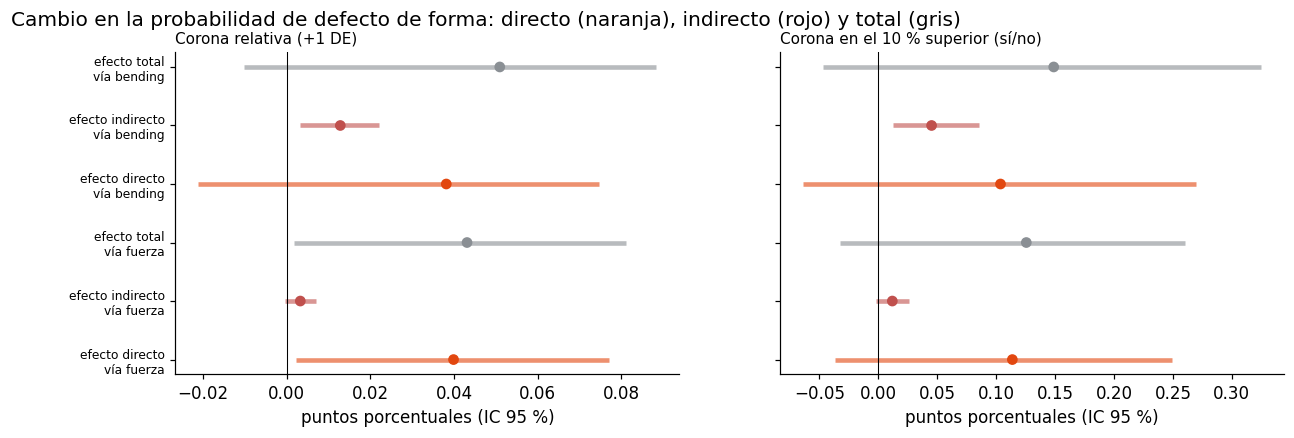

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for a, (trat, sub) in zip(ax, med[med.medida.isin(['efecto directo pp', 'efecto indirecto pp', 'efecto total pp'])].groupby('tratamiento', sort=False)):
    sub = sub.reset_index(drop=True)
    etiquetas = [f"{r.medida.replace(' pp', '')}\nvía {r.mediador.replace('_real', '')}" for r in sub.itertuples()]
    y = np.arange(len(sub))
    col = [COLORES['rojo'] if 'indirecto' in m else (COLORES['naranja'] if 'directo' in m else COLORES['gris']) for m in sub.medida]
    a.hlines(y, sub['IC bajo'], sub['IC alto'], color=col, lw=3, alpha=.6); a.scatter(sub['estimación'], y, color=col, zorder=3)
    a.axvline(0, color='k', lw=.7); a.set_yticks(y); a.set_yticklabels(etiquetas, fontsize=8)
    a.set_xlabel('puntos porcentuales (IC 95 %)'); a.set_title(trat, fontsize=10)
fig.suptitle('Cambio en la probabilidad de defecto de forma: directo (naranja), indirecto (rojo) y total (gris)', x=.01, ha='left')
guardar(fig, '06_mediacion'); plt.show()

**Cómo leerlo.** Cada fila es un efecto en **puntos porcentuales** de probabilidad de defecto de forma. El riesgo base es ~0.24 %, así que +0.1 pp equivale a ~40 % más riesgo relativo.
- **Directo** (naranja): lo que la corona hace sin pasar por el mediador.
- **Indirecto** (rojo): lo que pasa por la fuerza o el bending.
- **Total** (gris): la suma.

Si la barra cruza el 0, ese efecto no se distingue de cero.

### 2. Double Machine Learning
Implementación propia del estimador de residuos (modelo parcialmente lineal) con LightGBM y ajuste cruzado por programa del MC4. El error estándar está agrupado por programa.

In [6]:
PARAMS = dict(n_estimators=300, learning_rate=0.05, num_leaves=31, min_child_samples=100, subsample=0.8, subsample_freq=1,
              colsample_bytree=0.8, random_state=SEMILLA, verbose=-1)

def dml(df, T, Y, W, pliegues=pliegue, grupos_cl=cluster):
    y, t = df[Y].values.astype(float), df[T].values.astype(float)
    ok = ~np.isnan(t) & ~np.isnan(y)
    yh, th = np.full(len(df), np.nan), np.full(len(df), np.nan)
    for k in range(5):
        tr, va = (pliegues != k) & ok, (pliegues == k) & ok
        yh[va] = lgb.LGBMRegressor(**PARAMS).fit(df.loc[tr, W], y[tr]).predict(df.loc[va, W])
        th[va] = lgb.LGBMRegressor(**PARAMS).fit(df.loc[tr, W], t[tr]).predict(df.loc[va, W])
    u, v = (y - yh)[ok], (t - th)[ok]
    theta = (v * u).sum() / (v * v).sum()
    psi = v * (u - theta * v)
    S = pd.Series(psi).groupby(grupos_cl[ok]).sum()
    se = np.sqrt((S ** 2).sum()) / (v * v).sum()
    de_t = (df[T] - df.groupby('producto', observed=True)[T].transform('mean')).std()   # 1 DE dentro de producto
    return theta, se, de_t, ok.sum()

def fila(nombre, T, Y, W, escala=100, unidad='pp', df=None):
    df = d if df is None else df
    th, se, de, n = dml(df, T, Y, W)
    # Comparación ingenua: regresión simple dentro de producto, sin ajustar por W.
    zt = df[T] - df.groupby('producto', observed=True)[T].transform('mean'); zy = df[Y] - df.groupby('producto', observed=True)[Y].transform('mean')
    ok = zt.notna() & zy.notna(); naive = np.polyfit(zt[ok], zy[ok], 1)[0]
    return {'análisis': nombre, 'resultado': Y, 'eventos o piezas': int(df[Y].sum()) if df[Y].isin([0, 1]).all() else n,
            'unidad': unidad, 'efecto por 1 DE': escala * th * de, 'IC bajo': escala * (th - 1.96 * se) * de,
            'IC alto': escala * (th + 1.96 * se) * de, 'ingenuo dentro de producto': escala * naive * de, 'z': th / se}

W_BASE = ['producto'] + CONTROLES + MC4 + SKP_ENTRADA
dml_res = [
    fila('Fuerza real → forma', 'fuerza_real', 'b2_forma', W_BASE),
    fila('Fuerza real → forma (ajustando por bending real)', 'fuerza_real', 'b2_forma', W_BASE + ['bending_real']),
    fila('Bending real → forma', 'bending_real', 'b2_forma', W_BASE),
    fila('Bending real → forma (ajustando por fuerza real)', 'bending_real', 'b2_forma', W_BASE + ['fuerza_real']),
    fila('Corona relativa → forma (efecto total)', 'corona_relativa_pct', 'b2_forma', [w for w in W_BASE if w != 'corona_relativa_pct']),
    fila('Días MC4 → SKP → ΔFuerza', 'dias_mc4_skp', 'delta_fuerza', [w for w in W_BASE if w != 'dias_mc4_skp'], escala=1, unidad='kN'),
    fila('CONTROL NEGATIVO 1: fuerza real → metalúrgico', 'fuerza_real', 'b2_metalurgico', W_BASE),
    fila('CONTROL NEGATIVO 2: fuerza real → retención PESO (−)', 'fuerza_real', 'ret_peso_menos', W_BASE),
    # Para los días de espera: resultados que ocurrieron ANTES de la espera (la espera no puede causarlos).
    fila('CONTROL NEGATIVO 3: días → error de espesor del MC4', 'dias_mc4_skp', 'error_espesor_um',
         [w for w in W_BASE if w not in ('dias_mc4_skp', 'error_espesor_um')], escala=1, unidad='µm'),
    fila('CONTROL NEGATIVO 4: días → corona relativa del MC4', 'dias_mc4_skp', 'corona_relativa_pct',
         [w for w in W_BASE if w not in ('dias_mc4_skp', 'corona_relativa_pct')], escala=1, unidad='% del espesor'),
]
tab_dml = pd.DataFrame(dml_res)
tab_dml.round(4).to_csv(RESULTADOS / '06_dml.csv', index=False)
tab_dml.round(3)

,análisis,resultado,eventos o piezas,unidad,efecto por 1 DE,IC bajo,IC alto,ingenuo dentro de producto,z
0,Fuerza real → forma,b2_forma,101,pp,-0.015,-0.208,0.178,0.284,-0.149
1,Fuerza real → forma (ajustando por bending real),b2_forma,101,pp,-0.012,-0.215,0.191,0.284,-0.115
2,Bending real → forma,b2_forma,101,pp,-0.047,-0.148,0.054,-0.094,-0.914
3,Bending real → forma (ajustando por fuerza real),b2_forma,101,pp,-0.060,-0.160,0.039,-0.094,-1.190
4,Corona relativa → forma (efecto total),b2_forma,101,pp,0.090,-0.046,0.227,0.200,1.294
5,Días MC4 → SKP → ΔFuerza,delta_fuerza,43175,kN,49.445,39.550,59.339,60.685,9.795
6,CONTROL NEGATIVO 1: fuerza real → metalúrgico,b2_metalurgico,34,pp,-0.066,-0.119,-0.014,0.008,-2.480
7,CONTROL NEGATIVO 2: fuerza real → retención PE...,ret_peso_menos,532,pp,-0.419,-0.719,-0.120,0.295,-2.744
8,CONTROL NEGATIVO 3: días → error de espesor de...,error_espesor_um,43175,µm,0.010,-0.009,0.029,0.005,1.072
9,CONTROL NEGATIVO 4: días → corona relativa del...,corona_relativa_pct,42159,% del espesor,-0.020,-0.036,-0.003,-0.001,-2.288


In [7]:
# Sensibilidad: incluir el modo Fuerza (con el modo como confusor).
t2 = todo.copy()
for c in ['producto', 'usuario_skp']:
    t2[c] = t2[c].astype('category')
t2['modo_fuerza'] = (t2['modo'] == 'Fuerza').astype(int)
pl2, cl2 = t2['pliegue'].values, pd.factorize(t2['programa_mc4'])[0]
sens = []
for nombre, T in [('Fuerza real → forma (todos los modos)', 'fuerza_real'), ('Bending real → forma (todos los modos)', 'bending_real')]:
    th, se, de, n = dml(t2, T, 'b2_forma', W_BASE + ['modo_fuerza'], pliegues=pl2, grupos_cl=cl2)
    sens.append({'análisis': nombre, 'piezas': n, 'efecto por 1 DE (pp)': 100 * th * de,
                 'IC bajo': 100 * (th - 1.96 * se) * de, 'IC alto': 100 * (th + 1.96 * se) * de})
pd.DataFrame(sens).round(3)

,análisis,piezas,efecto por 1 DE (pp),IC bajo,IC alto
0,Fuerza real → forma (todos los modos),47409,-0.036,-0.208,0.135
1,Bending real → forma (todos los modos),47409,-0.037,-0.129,0.055


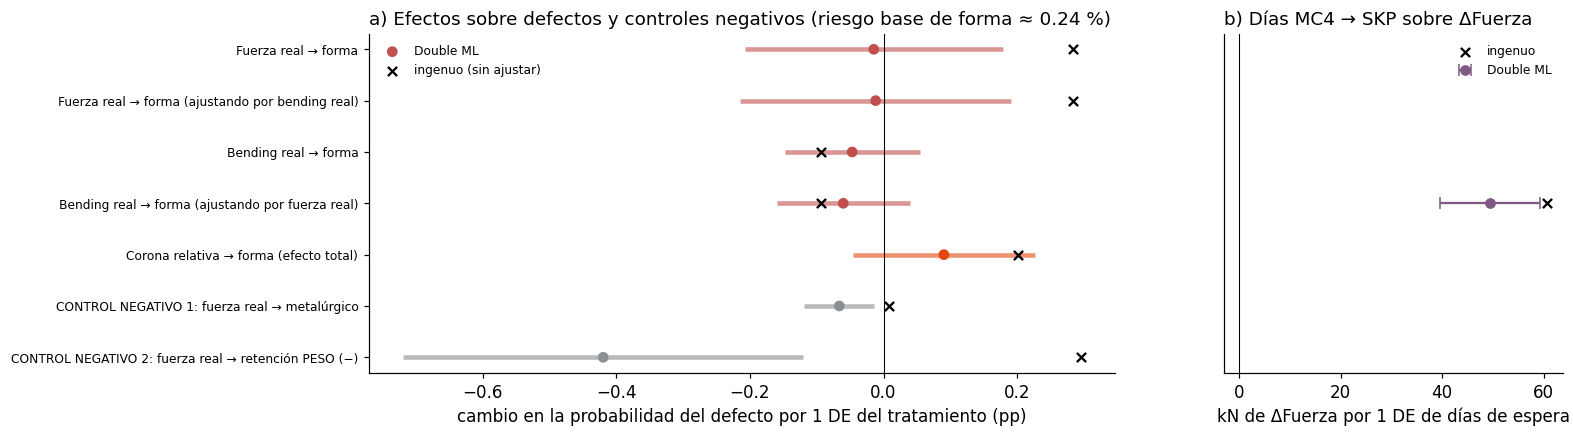

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={'width_ratios': [2.2, 1]})
pp = tab_dml[tab_dml['unidad'] == 'pp'].reset_index(drop=True)
y = np.arange(len(pp))[::-1]
col = [COLORES['gris'] if 'NEGATIVO' in a else (COLORES['naranja'] if 'Corona' in a else COLORES['rojo']) for a in pp['análisis']]
ax[0].hlines(y, pp['IC bajo'], pp['IC alto'], color=col, lw=3, alpha=.6)
ax[0].scatter(pp['efecto por 1 DE'], y, color=col, zorder=3, label='Double ML')
ax[0].scatter(pp['ingenuo dentro de producto'], y, marker='x', color='k', zorder=3, label='ingenuo (sin ajustar)')
ax[0].axvline(0, color='k', lw=.7); ax[0].set_yticks(y); ax[0].set_yticklabels(pp['análisis'], fontsize=8)
ax[0].set_xlabel('cambio en la probabilidad del defecto por 1 DE del tratamiento (pp)'); ax[0].legend(fontsize=8)
ax[0].set_title('a) Efectos sobre defectos y controles negativos (riesgo base de forma ≈ 0.24 %)')
r = tab_dml[tab_dml['resultado'] == 'delta_fuerza'].iloc[0]
ax[1].errorbar([r['efecto por 1 DE']], [0], xerr=[[r['efecto por 1 DE'] - r['IC bajo']], [r['IC alto'] - r['efecto por 1 DE']]],
               fmt='o', color='#7f5a83', capsize=4, label='Double ML')
ax[1].scatter([r['ingenuo dentro de producto']], [0], marker='x', color='k', label='ingenuo')
ax[1].axvline(0, color='k', lw=.7); ax[1].set_yticks([]); ax[1].set_xlabel('kN de ΔFuerza por 1 DE de días de espera')
ax[1].set_title('b) Días MC4 → SKP sobre ΔFuerza'); ax[1].legend(fontsize=8)
guardar(fig, '06_dml'); plt.show()

## E. Interpretación de los resultados

**1. Mediación: la cadena original (corona → sobreesfuerzo → defecto) no se sostiene.**
- **Primer eslabón:** una desviación estándar más de corona relativa sube la fuerza real solo 0.04 DE.
- **Efecto indirecto a través de la fuerza:** +0.003 pp (IC −0.000 a 0.007), prácticamente nulo. Para la corona en su 10 % superior: +0.012 pp, también no distinguible de cero.
- **Efecto total de la corona sobre forma:** pequeño. +0.043 pp por DE en el modelo de mediación (IC 0.002 a 0.081, apenas distinguible de cero); +0.09 pp en Double ML (IC −0.05 a 0.23, no distinguible). Con un riesgo base de ~0.24 %, el orden de magnitud sería de ~20-40 % más riesgo relativo por DE, pero con mucha incertidumbre.

**2. Un camino que no esperábamos: a través del bending.** Las piezas con más corona reciben **menos** bending real (a = −0.09 DE por DE de corona; −0.25 DE si la corona está en el 10 % superior), y menos bending se asocia con más defectos de forma. El efecto indirecto por esta vía es pequeño pero distinguible de cero: +0.013 pp (IC 0.003 a 0.022) y +0.045 pp para la cola de corona (IC 0.012 a 0.086). **Cuidado:** el segundo eslabón (bending → forma) no sobrevive en Double ML (IC −0.15 a 0.05) y, como se ve abajo, las estimaciones sobre variables del Skinpass fallan los controles negativos. Es una pista para el diseño experimental, no un resultado.

**3. Double ML sobre forma: las asociaciones del Notebook 05 desaparecen al ajustar.**
- **Fuerza real → forma:** la regresión ingenua dentro de producto daba +0.28 pp por DE; Double ML da −0.015 (IC −0.21 a 0.18). Lo que parecía un efecto de la fuerza lo explican los confusores (preset, operador, rodillo, producto).
- **Bending real → forma:** de −0.09 a −0.05 pp, no distinguible de cero.
- Incluir el modo Fuerza no cambia la conclusión.

**4. Los controles negativos fallan para los tratamientos del Skinpass.** Double ML estima que la fuerza real "reduce" los defectos metalúrgicos (−0.07 pp, z = −2.5) y la retención por PESO (−) (−0.42 pp, z = −2.7). Ninguno de los dos puede ser causado por la fuerza del Skinpass. Que ambos fallen, y en la misma dirección, indica **confusión no medida**: las piezas laminadas con más fuerza difieren de las demás en algo que los datos no registran (probablemente cómo se programa y se opera cada bloque). **Consecuencia: con estos datos no se pueden defender estimaciones causales del efecto de la fuerza o el bending sobre los defectos.** Hace falta un experimento.

**5. El resultado que sí resiste: los días de espera sobre ΔFuerza.**
- Double ML: **+49 kN por cada DE de espera** (IC 40 a 59 kN, z = 9.8), equivalente a 0.10 DE de ΔFuerza dentro de producto. La estimación ingenua era +61 kN: ajustar por confusores la reduce poco.
- **Controles negativos:** la espera no puede cambiar lo que pasó antes de ella. Su "efecto" sobre el error de espesor del MC4 es nulo (0.007 DE, IC incluye 0). Sobre la corona es de 0.019 DE: distinguible de cero por el tamaño de muestra, pero **5 veces menor** que el efecto sobre ΔFuerza.
- **Interpretación:** un rollo que espera más llega al Skinpass necesitando más fuerza de la que el setup prevé. Es compatible con un cambio del material durante la espera (envejecimiento o enfriamiento completo), aunque la explicación física requiere metalurgia, no estadística. El efecto es real pero **modesto**: unos 50 kN sobre una fuerza típica de ~4,000 kN.

## F. Conclusiones de la etapa

### Respuesta a la pregunta del mediador
> **La herencia del MC4 no produce defectos de forma a través de un sobreesfuerzo del Skinpass.** El efecto de la corona a través de la fuerza es prácticamente nulo. Hay una pista débil de un camino a través de un **menor bending** en piezas con más corona, que no se puede confirmar con datos históricos.

### Hallazgos principales
1. **Mediación por fuerza:** nula (+0.003 pp).
2. **Mediación por bending:** pequeña y frágil (+0.013 pp); candidata a probarse con un experimento.
3. **Efecto total de la corona sobre forma:** pequeño e incierto.
4. **Fuerza y bending → forma:** las asociaciones desaparecen al ajustar por confusores.
5. **Controles negativos:** fallan para los tratamientos del Skinpass → hay confusión no medida; estimaciones causales de esas variables no son defendibles con datos históricos.
6. **Días de espera → ΔFuerza:** +49 kN por DE, robusto y con controles negativos que pasan. Es el único efecto causal plausible de la herencia del MC4 sobre el esfuerzo.

### Decisiones tomadas
| Tema | Decisión |
|---|---|
| Afirmaciones causales sobre defectos | No se hacen; solo asociaciones. La validación debe ser experimental |
| Días de espera | Se reporta como efecto plausible (+49 kN por DE), con su mecanismo pendiente |
| Intervención B | Si se diseña, que pruebe el bending en piezas de corona alta, no el preset de fuerza |
| Experimento natural (Notebook 07) | Las campañas de rodillo son la mejor fuente de variación "casi aleatoria" que queda |

### Limitaciones
- 101 defectos de forma y 34 metalúrgicos: poco poder para eventos raros.
- La ignorabilidad condicional falla para las variables del Skinpass (controles negativos).
- La mediación supone además que no hay confusores entre mediador y resultado afectados por la corona.

### Qué sigue
El **Notebook 07** aprovecha el cambio de rodillos como experimento natural: comparar piezas del mismo producto al inicio y al final de campañas, controlando el ancho. Después, el **Notebook 08** diseña el experimento en planta, que es la única forma de resolver lo que los datos históricos no pueden.